In [1]:
pip install sqlalchemy psycopg2-binary pandas

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.comNote: you may need to restart the kernel to use updated packages.

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.8/2.8 MB 5.5 MB/s eta 0:00:01
   ------------------------------ --------- 2.1/2.8 MB 4.7 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 5.0 MB/s eta 0:00:00


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sqlalchemy import create_engine, text

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 2.2.3
NumPy version: 2.1.3


In [28]:
import os
print(os.path.exists(".env"))

True


In [29]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password=os.getenv("DB_PASSWORD"),   # type it here just for this test
    host="localhost",
    port=5432,
    database="ecommerce_analytics",
)
engine = create_engine(url)

with engine.connect() as conn:
    print(conn.execute(text("SELECT version();")).fetchone())

('PostgreSQL 18.6 on x86_64-windows, compiled by msvc-19.44.35228, 64-bit',)


In [30]:
df = pd.read_sql("SELECT * FROM ecommerce.customers LIMIT 10;", engine)
df.head(10)

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
5,879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
6,fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
7,5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
8,5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
9,4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


In [52]:
query = """
SELECT c.customer_unique_id,
       o.order_id,
       o.order_purchase_timestamp,
       SUM(p.payment_value) AS order_value
FROM ecommerce.orders o
JOIN ecommerce.customers c ON o.customer_id = c.customer_id
JOIN ecommerce.payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
GROUP BY c.customer_unique_id, o.order_id, o.order_purchase_timestamp;
"""
orders = pd.read_sql(query, engine, parse_dates=["order_purchase_timestamp"])
orders.info()
orders.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96477 entries, 0 to 96476
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   customer_unique_id        96477 non-null  object        
 1   order_id                  96477 non-null  object        
 2   order_purchase_timestamp  96477 non-null  datetime64[ns]
 3   order_value               96477 non-null  float64       
dtypes: datetime64[ns](1), float64(1), object(2)
memory usage: 2.9+ MB


,order_purchase_timestamp,order_value
count,96477,96477.000000
mean,2018-01-01 23:36:35.953657088,159.856357
min,2016-10-03 09:44:50,9.590000
25%,2017-09-14 09:09:57,61.880000
50%,2018-01-20 19:46:23,105.280000
75%,2018-05-05 18:56:01,176.330000
max,2018-08-29 15:00:37,13664.080000
std,NaN,218.813144


In [32]:
print(orders.shape)
print("Unique customers:", orders["customer_unique_id"].nunique())
print("Unique orders:", orders["order_id"].nunique())
print("Date range:", orders["order_purchase_timestamp"].min(), "to", orders["order_purchase_timestamp"].max())
print("Missing values:\n", orders.isna().sum())

(96477, 4)
Unique customers: 93357
Unique orders: 96477
Date range: 2016-10-03 09:44:50 to 2018-08-29 15:00:37
Missing values:
 customer_unique_id          0
order_id                    0
order_purchase_timestamp    0
order_value                 0
dtype: int64


In [38]:
snapshot = orders["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = orders.groupby("customer_unique_id").agg(
    last_order=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum"),
).reset_index()

rfm["recency"] = (snapshot - rfm["last_order"]).dt.days

In [39]:
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5,4,3,2,1])
rfm["F"] = pd.qcut(rfm["frequency"].rank(method= "first"), 5, labels = [1,2,3,4,5])
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels = [1,2,3,4,5])
rfm["RFM_score"] = rfm[["R", "F", "M"]].astype(str).agg("".join, axis = 1)

rfm.head()

#print((rfm["frequency"] == 1).mean().round(3))

,customer_unique_id,last_order,frequency,monetary,recency,R,F,M,RFM_score
0,0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,141.90,112,4,1,4,414
1,0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,27.19,115,4,1,1,411
2,0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,86.22,537,1,1,2,112
3,0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,43.62,321,2,1,1,211
4,0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,196.89,288,2,1,4,214


In [40]:
rfm["R"] = rfm["R"].astype(int)
rfm["M"] = rfm["M"].astype(int)

def segment(row):
    if row["frequency"] >= 2:
        return "Loyal Repeat Buyers" if row["R"] >= 3 else "Lapsed Repeat Buyers"
    if row["R"] >= 4 and row["M"] >= 2:
        return "New High Value"
    if row["R"] >= 4:
        return "New Customers"
    if row["M"] >= 4:
        return "At Risk High-Value"
    return "Lost/Low-Value"

rfm["segment"] = rfm.apply(segment, axis = 1)
rfm["segment"].value_counts()

segment
Lost/Low-Value          33673
New High Value          28906
At Risk High-Value      20659
New Customers            7318
Loyal Repeat Buyers      1813
Lapsed Repeat Buyers      988
Name: count, dtype: int64

In [41]:
summary = rfm.groupby("segment").agg(
    customers = ("customer_unique_id", "count"),
    avg_recency_days = ("recency", "mean"),
    avg_frequency = ("frequency", "mean"),
    avg_spend = ("monetary", "mean"),
    revenue = ("monetary", "sum") 
).round(1)

summary["customer_share %"] = (summary["customers"] / summary["customers"].sum() *100).round(1)
summary["revenue_share_%"] = (summary["revenue"] / summary["revenue"].sum() *100).round(1)
summary.sort_values("revenue", ascending = False)

,customers,avg_recency_days,avg_frequency,avg_spend,revenue,customer_share %,revenue_share_%
segment,,,,,,,
At Risk High-Value,20659,336.0,1.0,298.4,6164897.2,22.1,40.0
New High Value,28906,90.8,1.0,195.9,5663379.9,31.0,36.7
Lost/Low-Value,33673,337.7,1.0,72.5,2440199.6,36.1,15.8
Loyal Repeat Buyers,1813,132.0,2.1,317.5,575543.2,1.9,3.7
New Customers,7318,89.8,1.0,39.6,289627.8,7.8,1.9
Lapsed Repeat Buyers,988,382.3,2.1,292.3,288814.0,1.1,1.9


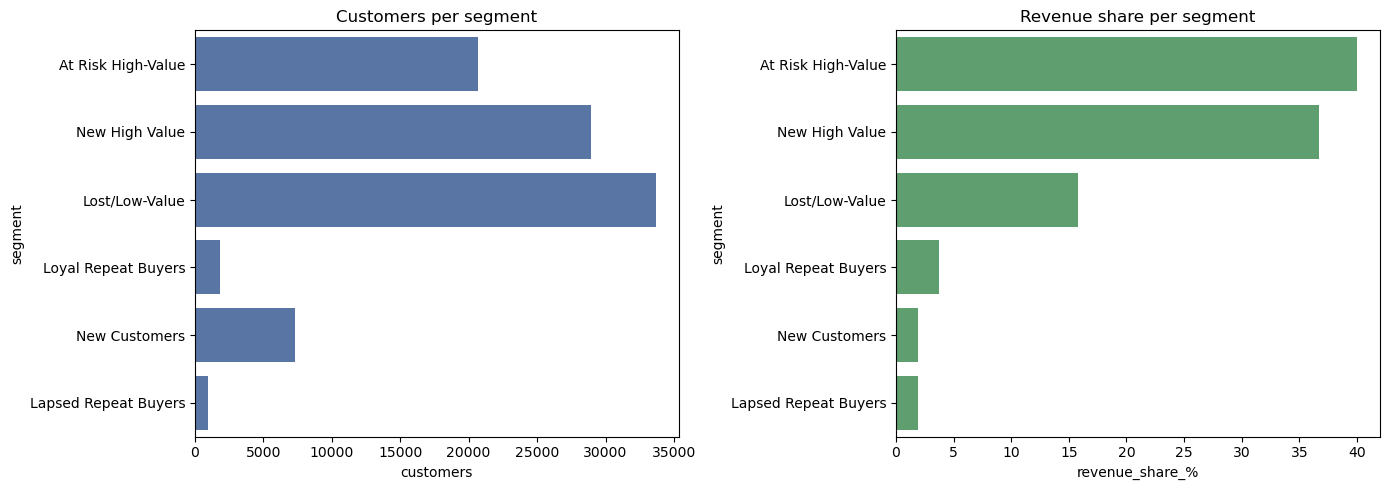

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

orders = summary.sort_values("revenue", ascending = False).index
fig, ax = plt.subplots(1,2, figsize = (14,5))
sns.barplot(x = summary.loc[orders, "customers"], y = orders, ax = ax[0], color = '#4C72B0')
ax[0].set_title("Customers per segment")

sns.barplot(x = summary.loc[orders, "revenue_share_%"], y = orders, ax = ax[1], color = "#55A868")
ax[1].set_title("Revenue share per segment")

plt.tight_layout()
plt.show()

In [46]:
repeat_rate = (rfm["frequency"] >= 2).mean() *100
print(f"Repeat purchase rate: {repeat_rate:.1f}%")

Repeat purchase rate: 3.0%


In [54]:
orders["order_month"] = orders["order_purchase_timestamp"].dt.to_period("M")
orders["cohort"] = orders.groupby("customer_unique_id")["order_month"].transform("min")
orders["period"] = (orders["order_month"] - orders["cohort"]).apply(lambda x: x.n)

cohort = (
    orders.groupby(["cohort", "period"])["customer_unique_id"]
    .nunique()
    .unstack(fill_value =0)
)

retention = cohort.div(cohort[0], axis = 0).round(3)
retention.head()

period,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort,,,,,,,,,,,,,,,,,,,,
2016-10,1.0,0.000,0.000,0.000,0.000,0.000,0.004,0.000,0.000,0.004,0.000,0.004,0.000,0.004,0.000,0.004,0.000,0.004,0.008,0.008
2016-12,1.0,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2017-01,1.0,0.003,0.003,0.001,0.004,0.001,0.004,0.001,0.001,0.000,0.004,0.001,0.007,0.004,0.001,0.001,0.003,0.004,0.001,0.000
2017-02,1.0,0.002,0.003,0.001,0.004,0.001,0.002,0.002,0.001,0.002,0.001,0.003,0.001,0.002,0.001,0.001,0.001,0.002,0.000,0.000
2017-03,1.0,0.004,0.004,0.004,0.004,0.002,0.002,0.003,0.003,0.001,0.004,0.001,0.002,0.001,0.002,0.002,0.001,0.001,0.000,0.000


In [56]:
retention_plot = retention.loc["2017-01":"2018-06", 0:6]

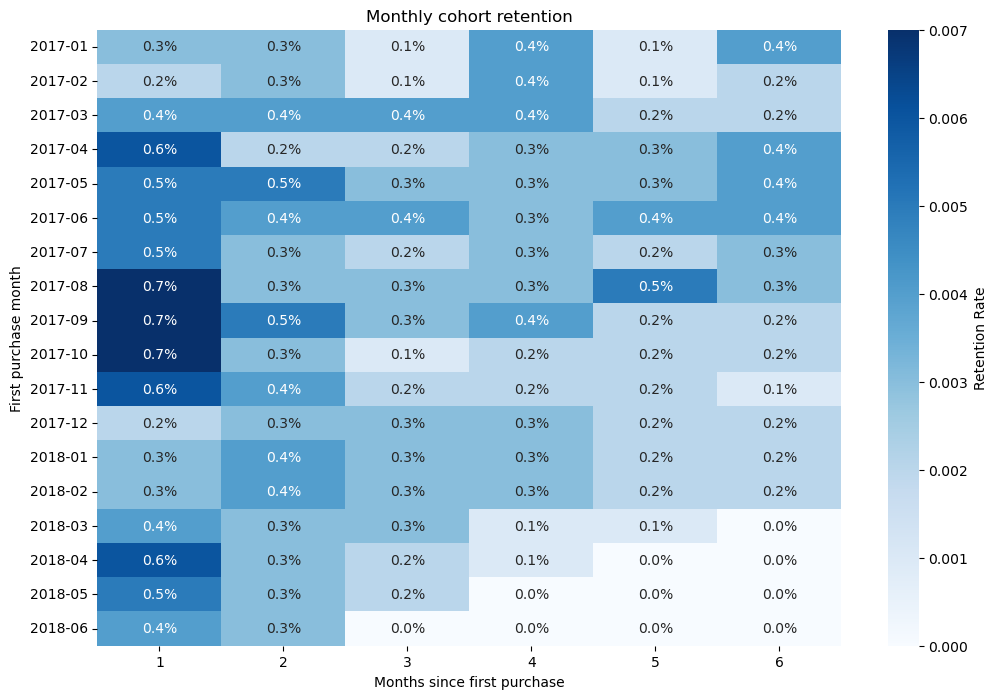

In [57]:
plt.figure(figsize = (12, 8))
sns.heatmap(
    retention_plot.iloc[:, 1:], 
    annot = True, fmt = ".1%", cmap="Blues", cbar_kws={"label": "Retention Rate"}
)
plt.title("Monthly cohort retention")
plt.xlabel("Months since first purchase")
plt.ylabel("First purchase month")
plt.show()

In [58]:
print("Avg month-1 retention: {:.2%}".format(retention_plot[1].mean()))

Avg month-1 retention: 0.47%


In [59]:
rfm.to_csv("../rfm_segments.csv", index=False)
retention.reset_index().assign(cohort=lambda d: d["cohort"].astype(str)).to_csv("../cohort_retention.csv", index=False)